<a href="https://colab.research.google.com/github/AsmaaaSalis/agriprice-teller-intelligence/blob/main/05_market_intelligence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 5: Market Intelligence Outputs

Turning the analysis into practical outputs for farmers and buyers in Borno and Yobe:
a seasonal price calendar, the price gap between the two states, how far the forecasts
can be trusted, and a short-term price outlook with a stated error range.
Prices are retail NGN per kg for millet, rice (local) and groundnuts, January 2016 to
October 2026. The outlook covers November 2026 to January 2027.

Inputs: clean_monthly_prices.csv (Notebook 2); forecasts_all_models.csv,
model_accuracy_results.csv and outlook_forecasts.csv (Notebook 4).

In [1]:
# Importing libraries

import pandas as pd              # Data tables
import numpy as np               # Missing values and maths
import matplotlib.pyplot as plt  # Charts

# Setting display options
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)

print('Libraries loaded')

Libraries loaded


### 1. Loading the files

In [2]:
# Loading the clean monthly prices (Notebook 2)
prices = pd.read_csv('clean_monthly_prices.csv', parse_dates=['date'])

# Loading the forecasts, accuracy results and outlook (Notebook 4)
forecasts = pd.read_csv('forecasts_all_models.csv', parse_dates=['origin', 'target'])
results = pd.read_csv('model_accuracy_results.csv')
outlook = pd.read_csv('outlook_forecasts.csv')

# Checking the size of each table (rows, columns)
print(prices.shape, forecasts.shape, results.shape, outlook.shape)

(780, 6) (1245, 12) (36, 7) (18, 14)


### 2. Seasonal price calendar
Which months are usually dearer or cheaper than the 12-month trend, for each crop.

In [3]:
# Sorting so each series runs in date order
prices = prices.sort_values(['state', 'commodity', 'date'])

# Calculating the 12-month moving average (local trend) for each state and crop
prices['trend'] = (prices.groupby(['state', 'commodity'])['price_per_kg_ngn']
                   .transform(lambda s: s.rolling(12, center=True, min_periods=9).mean()))

# Comparing each price with its trend, and averaging by calendar month and crop
prices['relative'] = prices['price_per_kg_ngn'] / prices['trend']
prices['month_num'] = prices['date'].dt.month
seasonal = prices.groupby(['month_num', 'commodity'])['relative'].mean().unstack()

# Converting to % above (+) or below (-) trend
seasonal_pct = ((seasonal - 1) * 100).round(1)
print(seasonal_pct)

commodity  Groundnuts  Millet  Rice (local)
month_num                                  
1                -3.7    -5.6          -4.2
2                -2.2    -4.5          -2.9
3                -0.4    -0.1          -0.1
4                -1.5    -1.7           0.1
5                -1.3    -3.0           1.8
6                -0.9     2.6          -0.5
7                 8.9    11.8           2.1
8                14.8    16.9           9.8
9                 4.0     3.0           3.4
10               -3.8    -9.5          -3.9
11               -5.7    -7.6          -3.4
12               -5.1    -5.9          -4.9


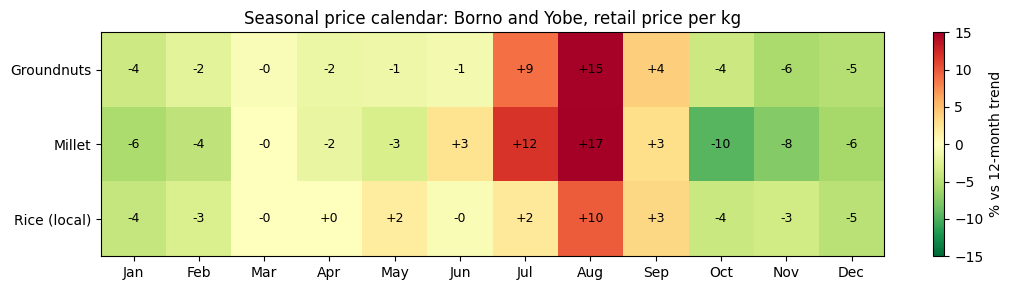

In [4]:
# Plotting the seasonal price calendar (red = usually dearer, green = usually cheaper)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(seasonal_pct.T.values, cmap='RdYlGn_r', vmin=-15, vmax=15, aspect='auto')
ax.set_xticks(range(12))
ax.set_xticklabels(month_names)
ax.set_yticks(range(len(seasonal_pct.columns)))
ax.set_yticklabels(seasonal_pct.columns)

# Writing the value in each cell
for i in range(len(seasonal_pct.columns)):
    for j in range(12):
        ax.text(j, i, f'{seasonal_pct.iloc[j, i]:+.0f}', ha='center', va='center', fontsize=9)

plt.colorbar(im, label='% vs 12-month trend')
ax.set_title('Seasonal price calendar: Borno and Yobe, retail price per kg')
plt.tight_layout()
plt.show()

### 3. Borno vs Yobe price gap
Yobe price as a % of Borno price: 100 = equal, below 100 = Yobe cheaper.

In [5]:
# Putting Borno and Yobe prices side by side
wide = prices.pivot_table(index=['date', 'commodity'], columns='state',
                          values='price_per_kg_ngn').reset_index()

# Keeping months when both states have a price, and calculating Yobe as a % of Borno
both = wide.dropna(subset=['Borno', 'Yobe']).copy()
both['yobe_pct_of_borno'] = both['Yobe'] / both['Borno'] * 100

# Summarising by crop
print(both.groupby('commodity')['yobe_pct_of_borno'].agg(['count', 'median', 'min', 'max']).round(0))

# Showing the yearly median gap
both['year'] = both['date'].dt.year
print(both.groupby(['year', 'commodity'])['yobe_pct_of_borno'].median().unstack().round(0))

              count  median   min    max
commodity                               
Groundnuts      111    83.0  59.0  166.0
Millet          111    83.0  60.0  172.0
Rice (local)    111    91.0  74.0  200.0
commodity  Groundnuts  Millet  Rice (local)
year                                       
2016             82.0    82.0          84.0
2017             92.0    96.0          95.0
2018             83.0   106.0          97.0
2019             71.0    73.0          92.0
2020             82.0    95.0          93.0
2021             71.0    96.0          94.0
2022             72.0    77.0          89.0
2023             89.0    79.0          90.0
2024             90.0    81.0          90.0
2025             91.0    84.0          85.0
2026             90.0    78.0          85.0


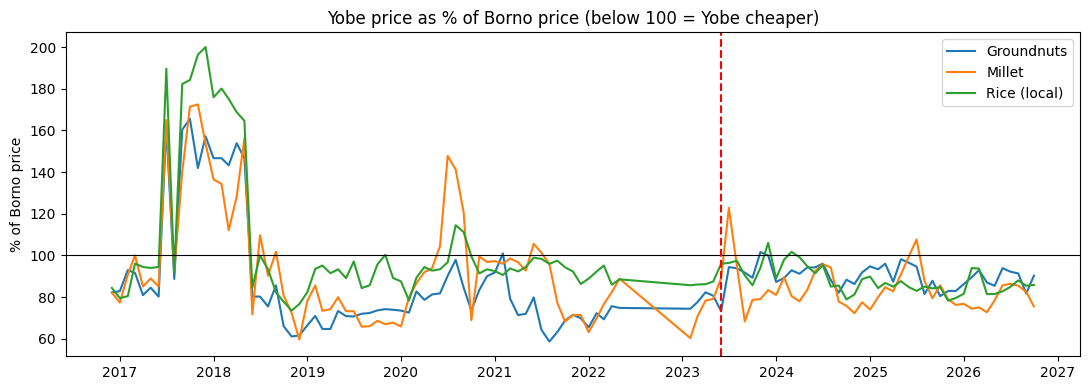

In [6]:
# Plotting Yobe price as a % of Borno price over time
fig, ax = plt.subplots(figsize=(11, 4))
for crop, g in both.groupby('commodity'):
    ax.plot(g['date'], g['yobe_pct_of_borno'], label=crop)
ax.axhline(100, color='black', linewidth=0.8)                       # equal prices
ax.axvline(pd.Timestamp('2023-06-01'), color='red', linestyle='--') # mid-2023
ax.set_title('Yobe price as % of Borno price (below 100 = Yobe cheaper)')
ax.set_ylabel('% of Borno price')
ax.legend()
plt.tight_layout()
plt.show()

### 4. How far can the forecasts be trusted?
Average % error (MAPE) by model and horizon, over the whole backtest and since mid-2023.

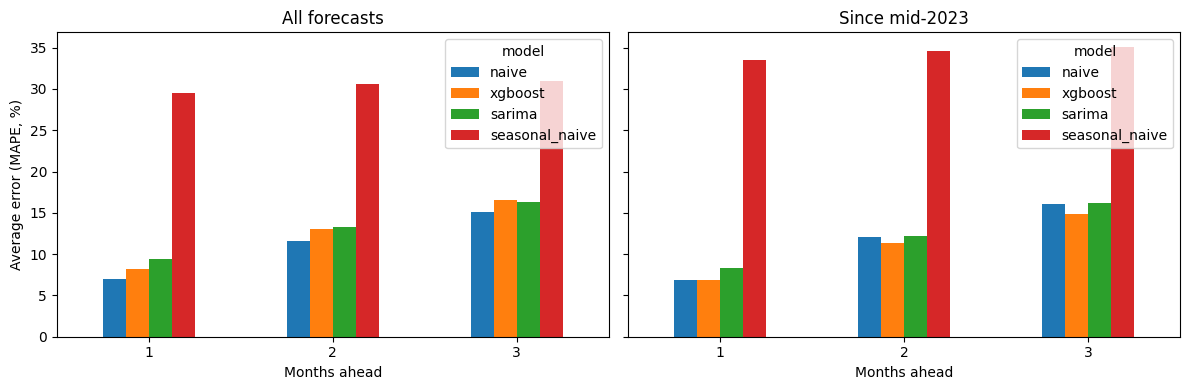

In [7]:
# Selecting MAPE for all periods and for the period from mid-2023
mape_all = results[results['period'] == 'all'].pivot_table(index='h', columns='model', values='MAPE')
mape_post = results[results['period'] == 'from 2023-06'].pivot_table(index='h', columns='model', values='MAPE')
order = ['naive', 'xgboost', 'sarima', 'seasonal_naive']

# Plotting average % error by model and horizon
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
mape_all[order].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('All forecasts')
axes[0].set_xlabel('Months ahead')
axes[0].set_ylabel('Average error (MAPE, %)')
mape_post[order].plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Since mid-2023')
axes[1].set_xlabel('Months ahead')
plt.tight_layout()
plt.show()

### 5. Price outlook: November 2026 to January 2027
XGBoost forecast per crop and state, with the typical error range from the backtest (since mid-2023).
The range is the average past error, not a guarantee: individual forecasts missed by more.

In [8]:
# Building a readable outlook table
view = outlook[['state', 'commodity', 'target', 'last_price', 'xgboost', 'xgboost_low', 'xgboost_high']].copy()
view['change_vs_last_%'] = (view['xgboost'] / view['last_price'] - 1) * 100
print(view.round(0).to_string(index=False))

state    commodity  target  last_price  xgboost  xgboost_low  xgboost_high  change_vs_last_%
Borno   Groundnuts 2026-11      1591.0   1559.0       1452.0        1666.0              -2.0
Borno   Groundnuts 2026-12      1591.0   1580.0       1400.0        1759.0              -1.0
Borno   Groundnuts 2027-01      1591.0   1525.0       1298.0        1753.0              -4.0
Borno       Millet 2026-11       459.0    463.0        431.0         495.0               1.0
Borno       Millet 2026-12       459.0    442.0        392.0         492.0              -4.0
Borno       Millet 2027-01       459.0    468.0        398.0         538.0               2.0
Borno Rice (local) 2026-11      1244.0   1242.0       1157.0        1328.0              -0.0
Borno Rice (local) 2026-12      1244.0   1253.0       1110.0        1395.0               1.0
Borno Rice (local) 2027-01      1244.0   1330.0       1132.0        1529.0               7.0
 Yobe   Groundnuts 2026-11      1436.0   1426.0       1328.0        15

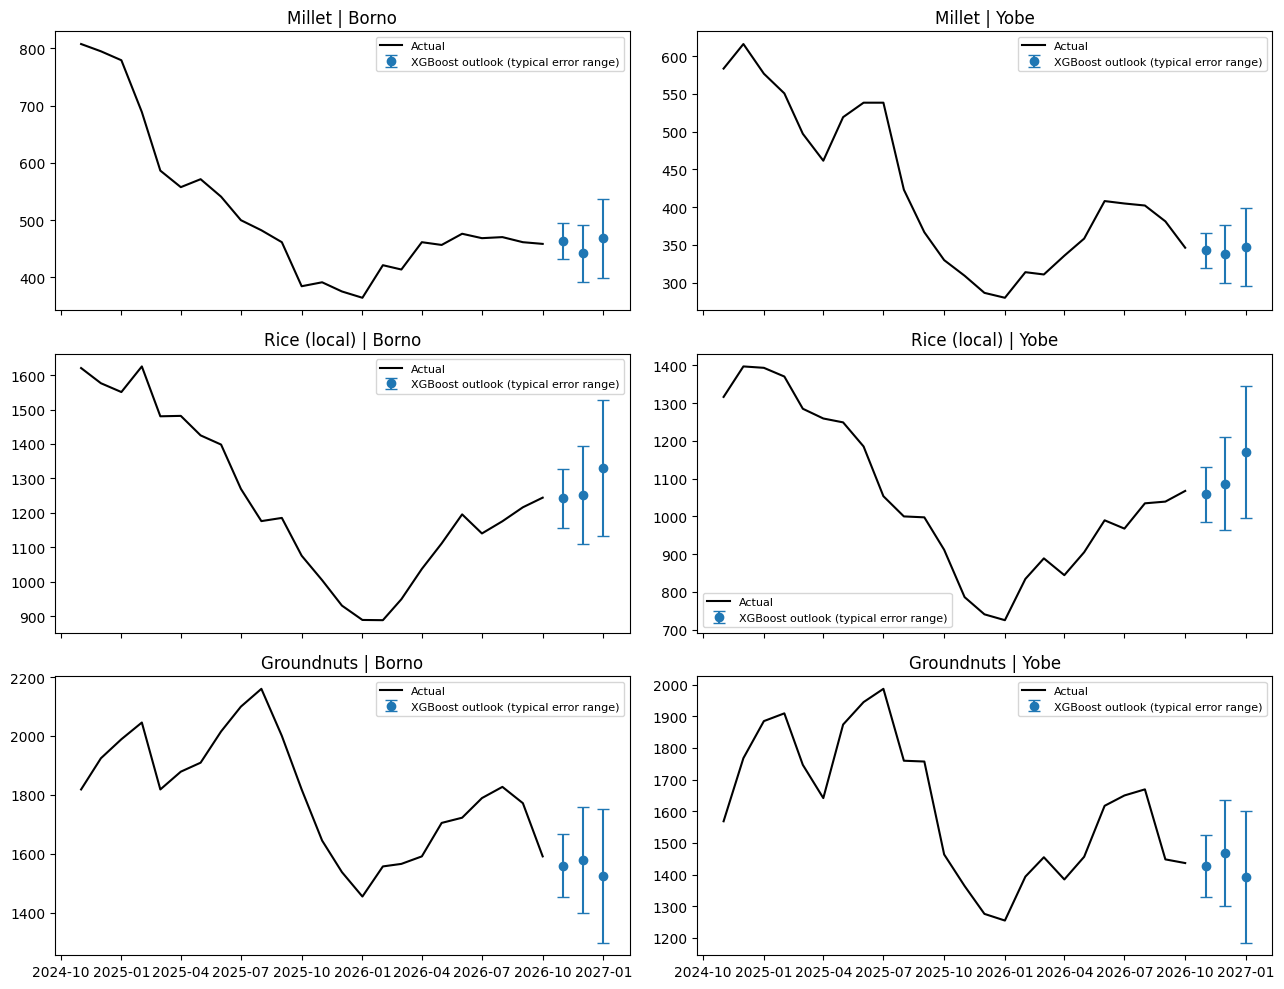

In [9]:
# Plotting the last 24 months of prices and the 3-month outlook with its error range
crops = ['Millet', 'Rice (local)', 'Groundnuts']
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)

for i, crop in enumerate(crops):
    for j, state in enumerate(['Borno', 'Yobe']):
        ax = axes[i, j]
        d = prices[(prices['commodity'] == crop) & (prices['state'] == state)
                   & (prices['date'] >= '2024-11-01')]
        ax.plot(d['date'], d['price_per_kg_ngn'], color='black', label='Actual')
        o = outlook[(outlook['commodity'] == crop) & (outlook['state'] == state)].copy()
        o['date'] = pd.to_datetime(o['target'] + '-01')
        ax.errorbar(o['date'], o['xgboost'],
                    yerr=[o['xgboost'] - o['xgboost_low'], o['xgboost_high'] - o['xgboost']],
                    fmt='o', capsize=4, label='XGBoost outlook (typical error range)')
        ax.set_title(f'{crop} | {state}')
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Market intelligence findings

- Seasonal calendar: prices are usually highest in August (up to +17% above trend for millet) and July, and lowest from October to December. This is the most dependable output, because it describes a pattern repeated over about ten years and does not depend on an exact forecast.
- Borno vs Yobe: Yobe is usually cheaper (about 83% of Borno's price for groundnuts and millet, 91% for rice), but the gap changes from year to year and month to month, so it should not be read as a fixed discount. Transport, security and market access are not in the data.
- Forecast reliability: the typical 1-month error is about 7% and the 3-month error about 15%. The simple baseline is hard to beat, so forecasts should be read as context, not as a price guarantee.
- Outlook for November 2026 to January 2027: prices are expected to stay close to October 2026 levels. Each forecast carries the typical backtest error range, which is the average past error, not a guarantee.
- What would make this more reliable: weekly rather than monthly data, farm-gate prices, more markets and states, drivers such as fuel and exchange-rate data, and testing with farmers and traders.